# ممیزی فاز اول، مسیر ب
محمدرضا استادعظیم — 401100025

This notebook displays actual computed outputs. Run `python -m src.audit` to regenerate the source tables and figures. All value-level EDA below is training-only; schema and modality availability audit the complete accepted inputs.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
ROOT = Path.cwd()
if not (ROOT / 'configs/phase1.json').exists():
    ROOT = ROOT.parent
if not (ROOT / 'configs/phase1.json').exists():
    raise RuntimeError('Open from the project root or notebooks directory')
sys.path.insert(0, str(ROOT))
from src.data_io import verify_sources
print('Verified official input files:', len(verify_sources(ROOT)))
summary = json.loads((ROOT / 'reports/phase1/audit_summary.json').read_text(encoding='utf-8'))
print('Student:', summary['identity']['name'], summary['identity']['student_id'])

Verified official input files: 4
Student: محمدرضا استادعظیم 401100025


## 1. Provenance and structure
The source hashes are pinned, not recomputed to silently accept changing inputs.

In [2]:
print(pd.read_csv(ROOT / 'tables/source_inventory.csv').to_string(index=False))
print(pd.read_csv(ROOT / 'tables/category_inventory.csv').to_string(index=False))

                                file               category     kind  rows  fields  compressed_bytes
     Magazine_Subscriptions.jsonl.gz Magazine_Subscriptions  reviews 71497      10           9986670
meta_Magazine_Subscriptions.jsonl.gz Magazine_Subscriptions metadata  3391      16            675250
         Subscription_Boxes.jsonl.gz     Subscription_Boxes  reviews 16216      10           2702022
    meta_Subscription_Boxes.jsonl.gz     Subscription_Boxes metadata   641      14            283011
              category  rows  unique_users  products  variant_asins              earliest_utc                       latest_utc  metadata_join_pct
Magazine_Subscriptions 70922         60144      3391           3391 2001-10-26T19:41:06+00:00 2023-08-15T21:57:59.736000+00:00                100
    Subscription_Boxes 16015         15236       641           1128 2017-01-24T23:57:59+00:00 2023-08-30T23:13:26.732000+00:00                100


## 2. Quality decisions
Exact raw copies are deduplicated. Different rows sharing user/product/time are quarantined together. Original files stay unchanged.

In [3]:
print(pd.read_csv(ROOT / 'tables/quality_issues.csv').to_string(index=False))
print('Diagnostics:', json.dumps(summary['diagnostics'], indent=2))

                         issue  count
               raw_review_rows  87713
        exact_duplicate_excess    774
    business_key_conflict_rows      2
           invalid_rating_rows      0
        invalid_parent_id_rows      0
       invalid_variant_id_rows      0
          missing_user_id_rows      0
        invalid_timestamp_rows      0
     invalid_helpful_vote_rows      0
invalid_verified_purchase_rows      0
              quarantined_rows      2
Diagnostics: {
  "text_iqr_upper_fence_train": 106.5,
  "helpful_vote_iqr_upper_fence_train": 7.5,
  "top_10_products_train_share": 0.17740940246485332,
  "repeated_user_product_pairs": 38,
  "normalized_long_text_duplicate_excess": 1043,
  "metadata_exact_duplicate_excess": 0,
  "raw_json_parse_errors": 0,
  "join_unmatched_reviews": 0,
  "train_non_ascii_rows": 4196,
  "train_missing_body_rows": 8,
  "train_very_short_rows": 6316,
  "train_very_long_rows": 1398,
  "valid_numeric_prices": 0,
  "raw_nonnull_prices": 1,
  "train_word_count

## 3. Availability of each modality
URL presence is not downloaded pixel availability. Product and review denominators are separate.

In [4]:
print(pd.read_csv(ROOT / 'tables/modality_availability.csv').to_string(index=False))
print(pd.read_csv(ROOT / 'tables/missingness_category_association.csv').to_string(index=False))

   unit               category          modality  available  denominator  available_pct  missing_pct
 review Magazine_Subscriptions          has_text      70921        70922      99.998590     0.001410
 review Magazine_Subscriptions  has_review_title      70922        70922     100.000000     0.000000
 review Magazine_Subscriptions  has_review_image        220        70922       0.310200    99.689800
 review Magazine_Subscriptions      has_metadata      70922        70922     100.000000     0.000000
 review Magazine_Subscriptions has_product_image      70922        70922     100.000000     0.000000
 review Magazine_Subscriptions         has_price          0        70922       0.000000   100.000000
 review Magazine_Subscriptions     has_timestamp      70922        70922     100.000000     0.000000
 review Magazine_Subscriptions   has_interaction      70922        70922     100.000000     0.000000
 review     Subscription_Boxes          has_text      16004        16015      99.931314    

## 4. Training-only EDA
Non-ASCII is an encoding/script flag, not a language prediction. Outliers remain in the audit.

In [5]:
print(pd.read_csv(ROOT / 'tables/train_numeric_summary.csv').to_string(index=False))
print(pd.read_csv(ROOT / 'tables/train_text_audit.csv').to_string(index=False))

              category     variable     n       mean        std  min  q25  median  q75   p95     p99   max
Magazine_Subscriptions   word_count 48378  39.028298  62.141282    0    8      22   44 137.0  286.00  2921
Magazine_Subscriptions   char_count 48378 218.688700 355.596120    0   45     119  245 771.0 1628.46 16898
Magazine_Subscriptions       rating 48378   4.041134   1.457050    1    3       5    5   5.0    5.00     5
Magazine_Subscriptions helpful_vote 48378   4.395717  29.156811    0    0       0    2  15.0   68.00  2169
    Subscription_Boxes   word_count 11585  46.812689  56.305033    0   13      30   59 144.0  273.16   865
    Subscription_Boxes   char_count 11585 248.926970 301.885020    0   69     158  312 771.8 1488.96  4535
    Subscription_Boxes       rating 11585   3.729996   1.554251    1    2       5    5   5.0    5.00     5
    Subscription_Boxes helpful_vote 11585   5.625896  15.408169    0    0       2    6  20.0   54.00   647
              category             fl

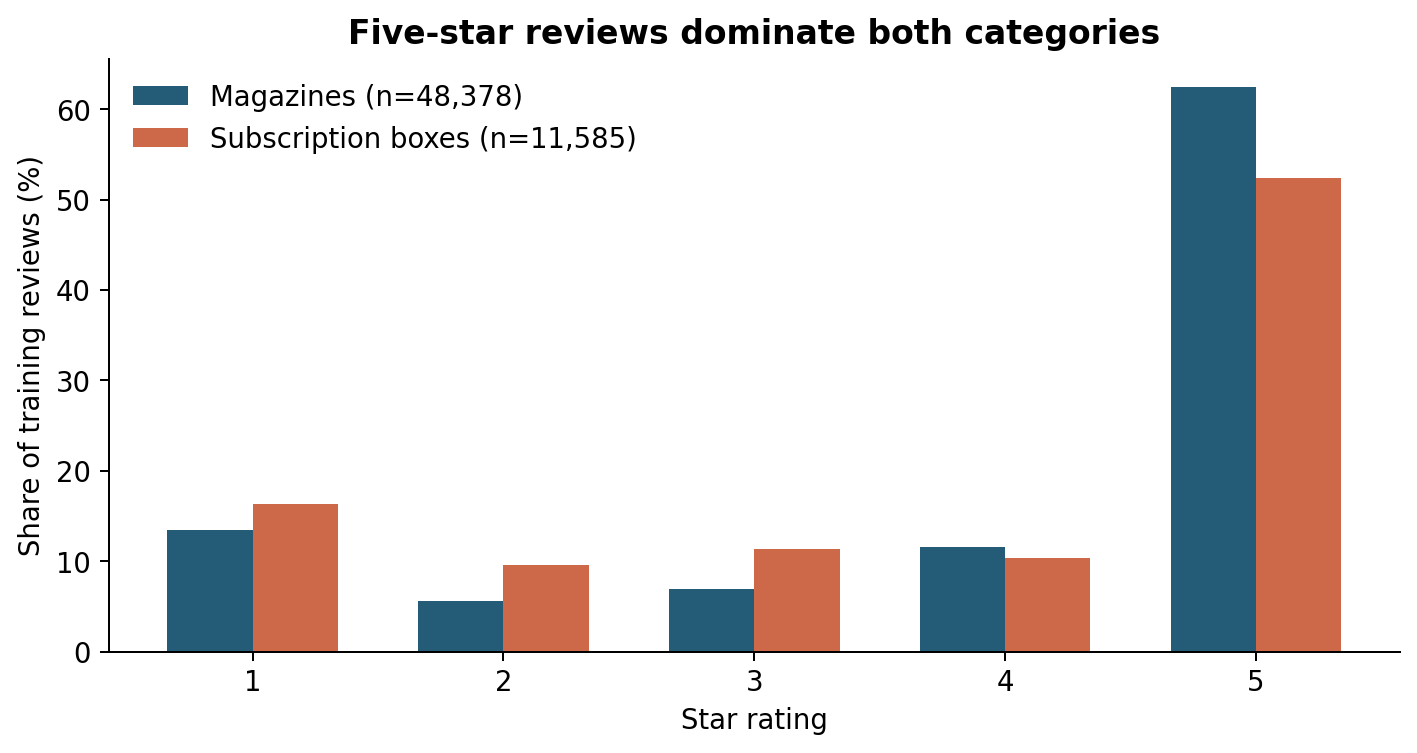

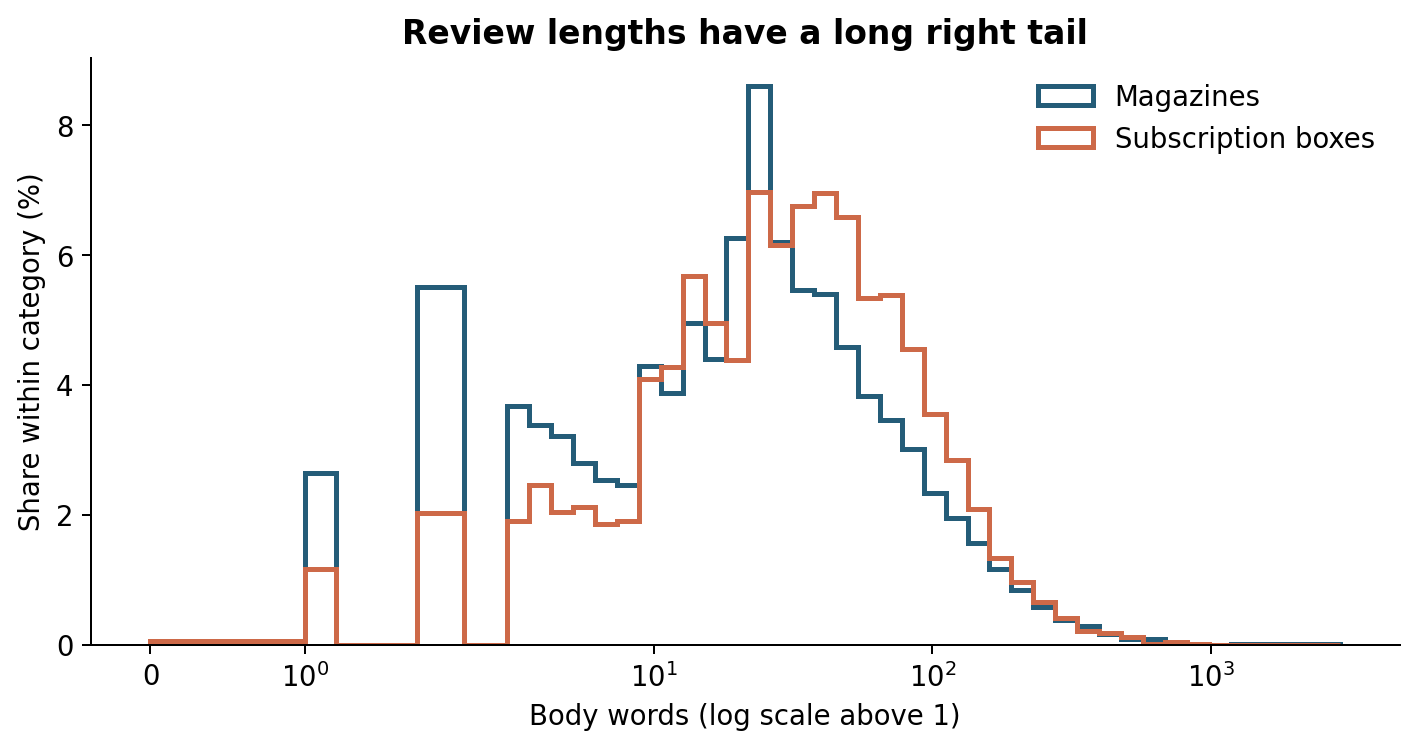

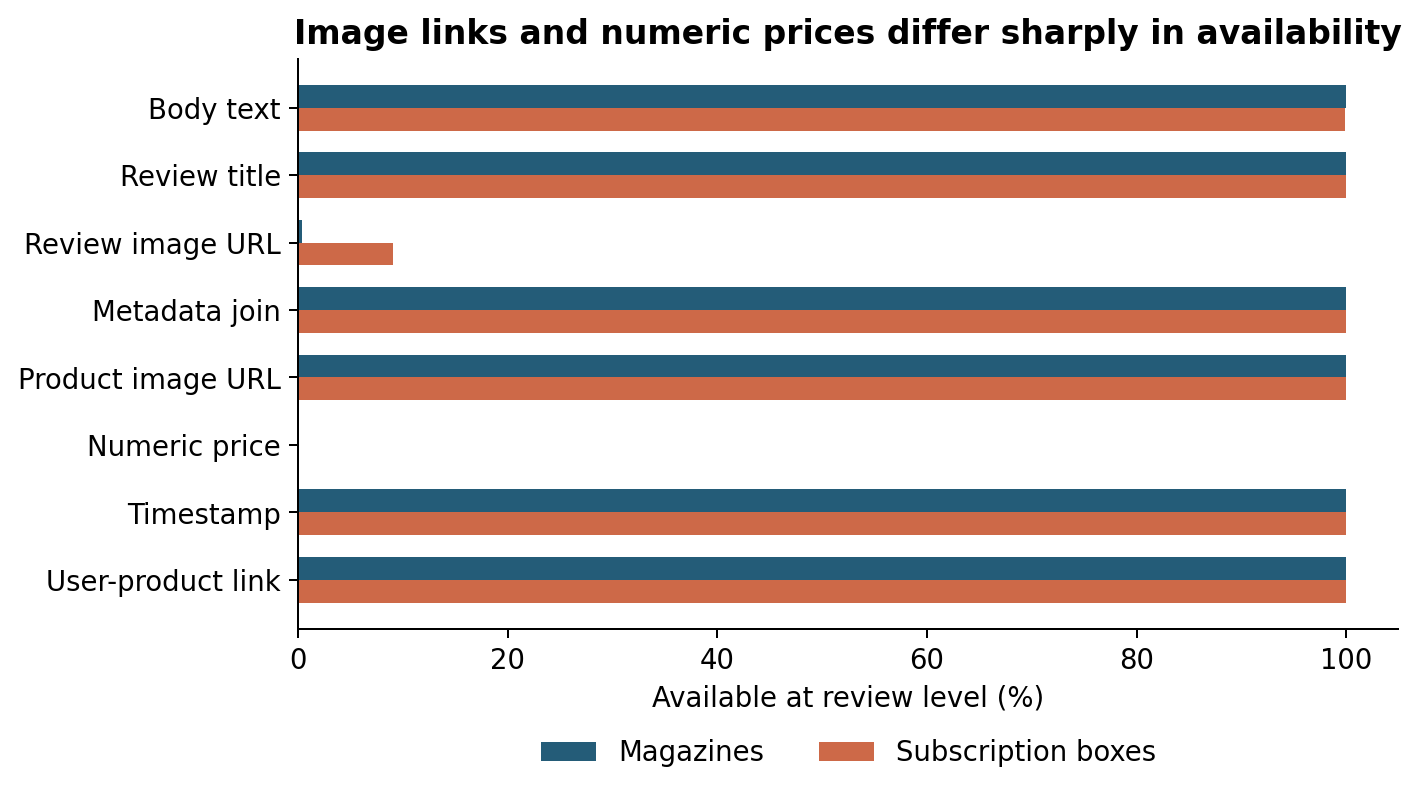

In [6]:
def show_plot(name):
    from IPython.display import display, Image
    display(Image(filename=str(ROOT / 'figures' / (name + '.png'))))
show_plot('01_rating_distribution')
show_plot('02_text_length')
show_plot('03_modalities')

## 5. Multivariable relationships
Associations do not identify causal effects. Row counts accompany every subgroup rate.

              category          x            y  spearman_rho
                   ALL word_count       rating     -0.234683
                   ALL word_count helpful_vote      0.478717
Magazine_Subscriptions word_count       rating     -0.234773
Magazine_Subscriptions word_count helpful_vote      0.488162
    Subscription_Boxes word_count       rating     -0.188371
    Subscription_Boxes word_count helpful_vote      0.363978
       source_category length_bin     n  negative_n  negative_rate
Magazine_Subscriptions        0-3  5718         370       0.064708
Magazine_Subscriptions       4-10  9029        1137       0.125928
Magazine_Subscriptions      11-30 16051        2839       0.176874
Magazine_Subscriptions     31-100 13482        3477       0.257899
Magazine_Subscriptions    101-200  2987         989       0.331101
Magazine_Subscriptions       201+  1111         384       0.345635
    Subscription_Boxes        0-3   598          75       0.125418
    Subscription_Boxes       4-10  16

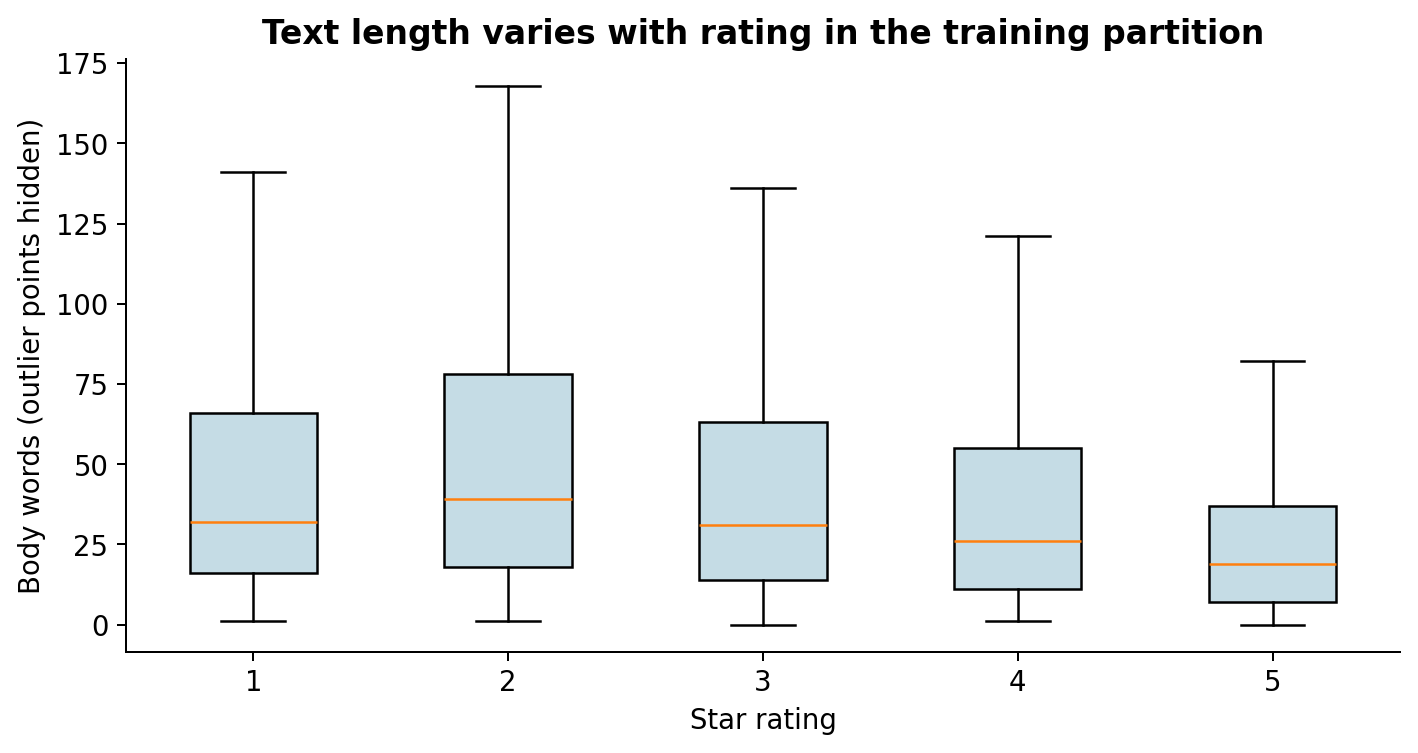

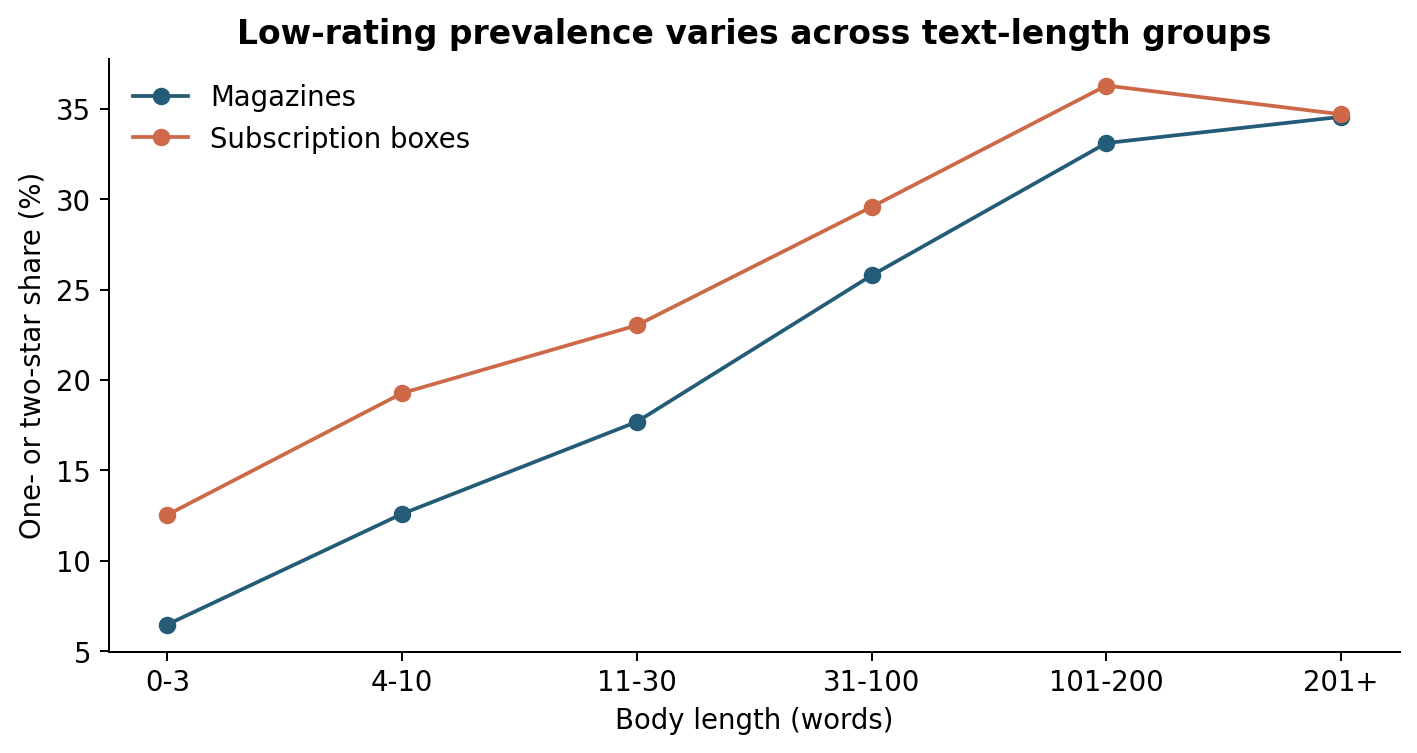

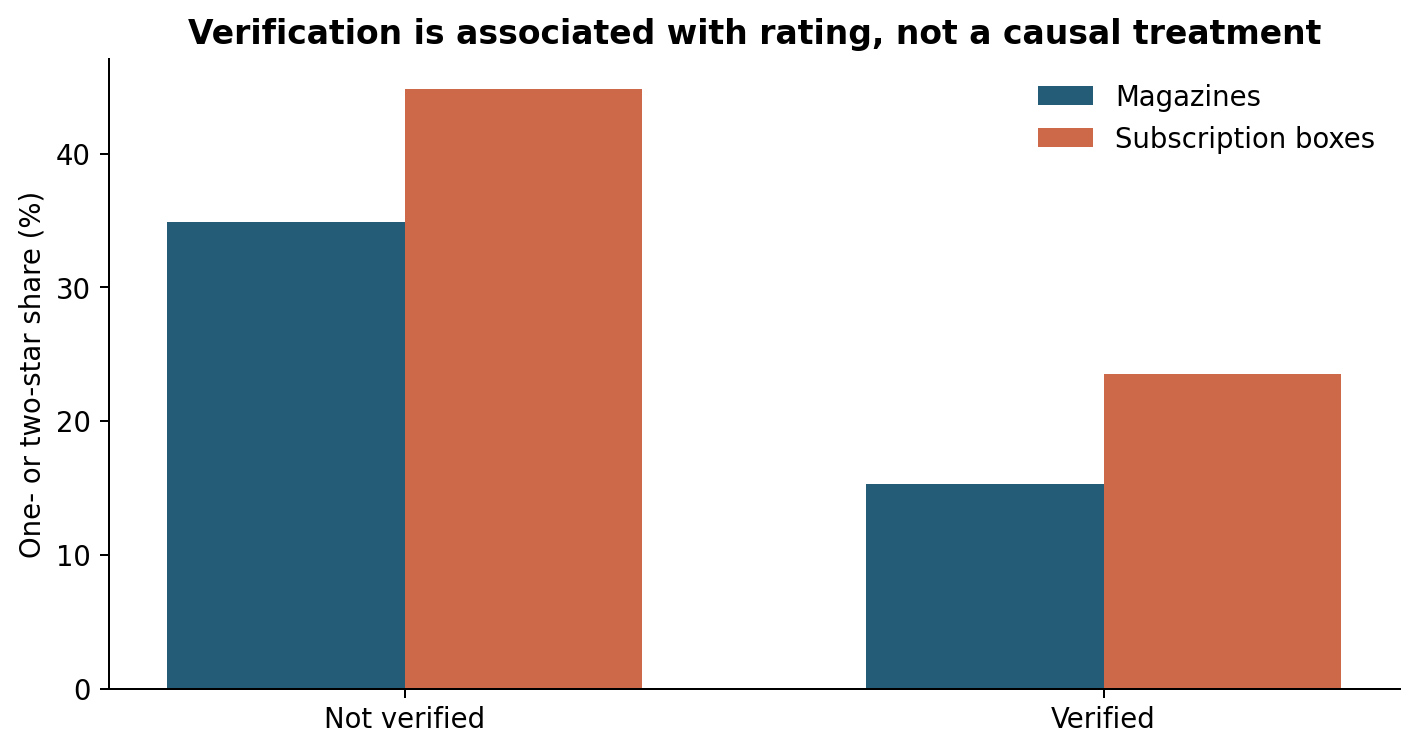

In [7]:
print(pd.read_csv(ROOT / 'tables/train_correlations.csv').to_string(index=False))
print(pd.read_csv(ROOT / 'tables/train_negative_by_length.csv').to_string(index=False))
print(pd.read_csv(ROOT / 'tables/train_negative_by_verified.csv').to_string(index=False))
show_plot('04_length_rating')
show_plot('06_negative_by_length')
show_plot('08_verified_rating')

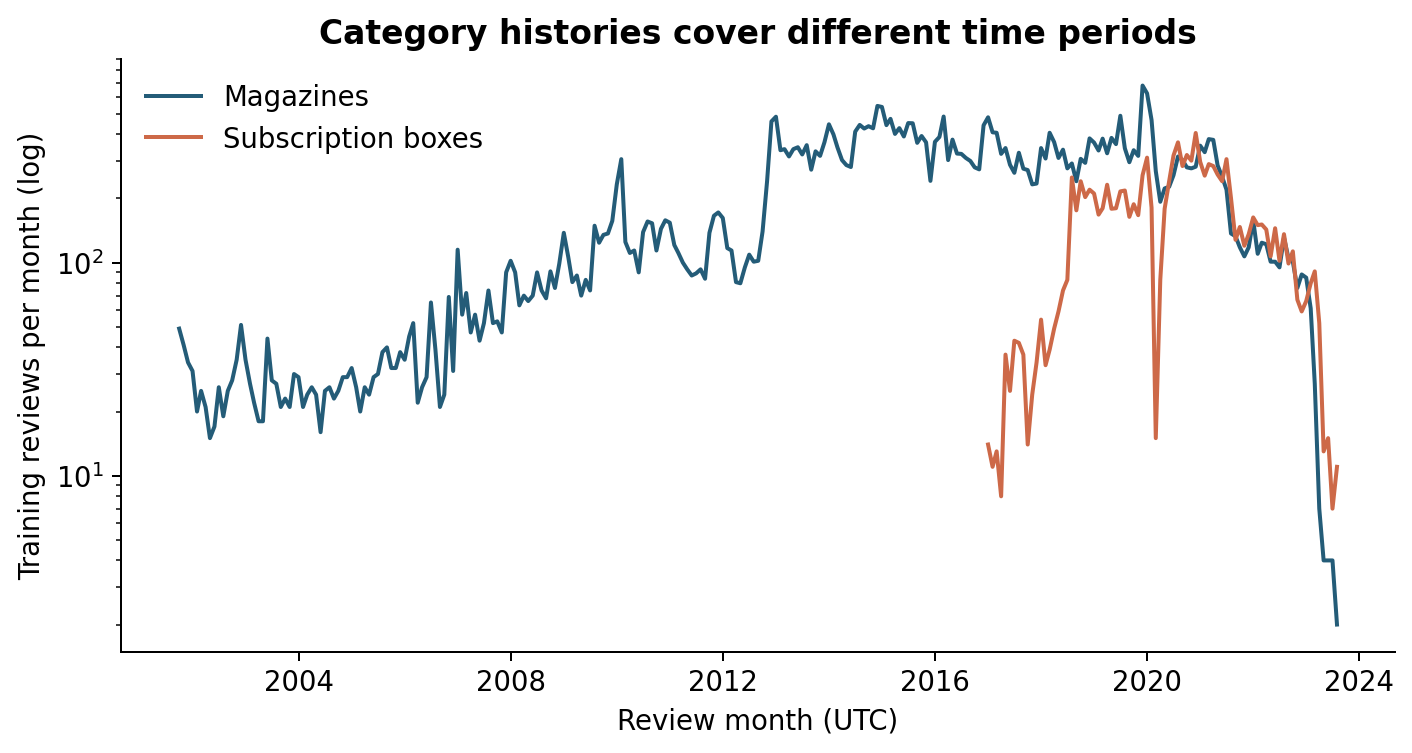

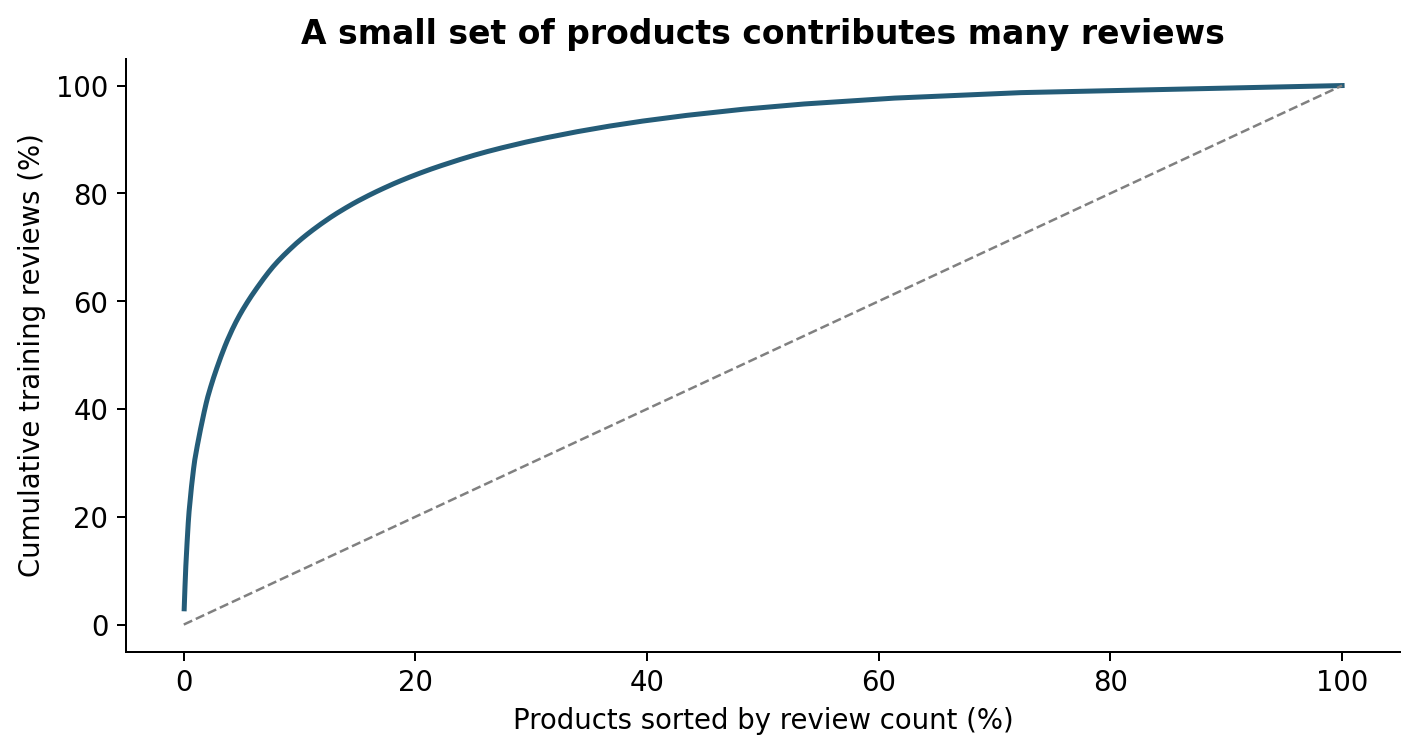

In [8]:
show_plot('05_monthly_activity')
show_plot('07_product_concentration')

## 6. Split integrity and baseline references
Products never cross partitions. Exact normalized title+body copies with at least five words are purged from lower-priority partitions without consulting ratings. User overlap is allowed for product cold-start, and is disclosed. These baseline values are training references, not held-out predictions.

In [9]:
print(json.dumps(summary['split'], indent=2))
print(json.dumps(summary['baseline'], indent=2))
assert all(x == 0 for x in summary['split']['product_overlap'].values())
assert all(x == 0 for x in summary['split']['long_exact_text_overlap_after_purge'].values())
print('No predictive model was fitted in phase one.')

{
  "before_purge_rows": {
    "test": 15931,
    "train": 59963,
    "validation": 11043
  },
  "retained_rows": {
    "test": 15669,
    "train": 59963,
    "validation": 10912
  },
  "retained_products": {
    "test": 612,
    "train": 2842,
    "validation": 563
  },
  "purged_rows": 393,
  "product_overlap": {
    "train_validation": 0,
    "train_test": 0,
    "validation_test": 0
  },
  "long_exact_text_overlap_after_purge": {
    "train_validation": 0,
    "train_test": 0,
    "validation_test": 0
  },
  "user_overlap": {
    "train_validation": 1459,
    "train_test": 2641,
    "validation_test": 581
  },
  "note": "User overlap is permitted for product cold-start. No user identifier or per-user target aggregate is a model input. Near-duplicates remain a limitation."
}
{
  "scope": "training descriptive reference only; not held-out model performance",
  "n": 59963,
  "negative_count": 12194,
  "negative_prevalence": 0.2033587378883645,
  "majority_class": 0,
  "majority_traini

## 7. Next phases and disclosure
See PROJECT_CARD.md for the frozen question, three candidate questions, metrics, leakage controls and planned TF-IDF/SVD/clustering. See AI_USAGE.md for substantial AI assistance. Review the report and source code before defending the work.